# S3 — Contrat JSON & Prompts
## Assistant Pédagogique RL/GRPO — ESIEE Paris 2025/2026

**Objectif de la semaine 3 :**
- Formaliser le **contrat de sortie JSON** (schéma strict à 5 champs)
- Comparer les 3 stratégies de prompting
- Atteindre **≥ 95% de format JSON valide** sur les 45 questions
- Valider le gate **GO S3** avant de passer au benchmark S4


---
## 1. Contrat de sortie JSON

Le modèle doit répondre **uniquement** avec un objet JSON respectant ce schéma :

```json
{
  "reformulation":   "Reformulation concise de la demande de l'étudiant",
  "reasoning_steps": ["étape 1", "étape 2", "étape 3"],
  "example":         "Exemple minimal concret (code Python si pertinent)",
  "verification":    "Vérification concrète à réaliser",
  "limitations":     "Limites, hypothèses ou incertitudes"
}
```

| Champ | Type | Contrainte | Rôle pédagogique |
|-------|------|------------|------------------|
| `reformulation` | string | non vide | Montrer que le modèle a compris |
| `reasoning_steps` | array | ≥ 1 élément | Traçabilité du raisonnement |
| `example` | string | non vide | Ancrage concret |
| `verification` | string | non vide | Incite l'étudiant à tester |
| `limitations` | string | non vide | Honnêteté épistémique |

> **Règle d'or prof (B. Tajini) : structure avant style.**


In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(".").resolve()
for c in [ROOT, ROOT.parent]:
    if (c / "assistant_raisonnement_avance").exists():
        ROOT = c; break
PROJ = ROOT / "assistant_raisonnement_avance"
sys.path.insert(0, str(PROJ))

from app.prompts import PROMPTS
from app.assistant_core import validate_four_block_response

df = pd.read_csv(ROOT / "resultats" / "eval_results.csv", encoding="utf-8")
COLORS = {"baseline":"#6c757d","structured":"#0d6efd","fewshot":"#198754"}
ORDER  = ["baseline","structured","fewshot"]
print(f"Données chargées : {len(df)} lignes | {df['id'].nunique()} questions | {df['strategy'].nunique()} stratégies")


Données chargées : 135 lignes | 45 questions | 3 stratégies


---
## 2. Les 3 stratégies de prompting

| Stratégie | Description | JSON forcé |
|-----------|-------------|------------|
| `baseline` | Instruction libre, pas de format | ❌ |
| `structured` | Schéma JSON explicite dans le prompt | ✅ |
| `fewshot` | Schéma JSON + exemple de réponse complète | ✅ |


In [2]:
# ── Affichage des prompts ─────────────────────────────────────────────────────
for name in ["baseline","structured","fewshot"]:
    print(f"{'='*60}")
    print(f"[{name.upper()}]")
    print(PROMPTS[name][:500])
    print("..." if len(PROMPTS[name]) > 500 else "")
    print()


[BASELINE]
Tu es un assistant utile. Réponds clairement à la question de l'étudiant.

Question:
{question}



[STRUCTURED]
Tu es un assistant pédagogique spécialisé en cybersécurité.

Réponds UNIQUEMENT avec un objet JSON valide respectant exactement ce schéma :
{
  "reformulation": "Reformulation concise de la demande",
  "reasoning_steps": ["étape 1", "étape 2", "étape 3"],
  "example": "Exemple minimal pertinent",
  "verification": "Vérification concrète à réaliser",
  "limitations": "Limites, hypothèses ou incertitudes"
}

Règles :
- "reformulation" : reformule la question en une phrase concise.
- "reasoning_ste
...

[FEWSHOT]
Tu es un assistant pédagogique spécialisé en cybersécurité.

Réponds UNIQUEMENT avec un objet JSON valide respectant exactement ce schéma :
{
  "reformulation": "Reformulation concise de la demande",
  "reasoning_steps": ["étape 1", "étape 2", "étape 3"],
  "example": "Exemple minimal pertinent",
  "verification": "Vérification concrète à réaliser",
  "limita

---
## 3. Résultats après correction du rate-limiting

**Problème détecté en S2 :** ~18 questions recevaient des réponses vides (latence ~240ms)
causées par le rate-limiting de l'API Groq en fin de batch.

**Correction appliquée :** logique de retry avec backoff exponentiel dans `GroqModelClient`.


In [3]:
# ── Tableau comparatif final ──────────────────────────────────────────────────
summary = (df.groupby("strategy")
           .agg(N=("overall","count"),
                Score_moyen=("overall","mean"),
                JSON_pct=("valid_format","mean"),
                Latence_ms=("latency_ms","mean"),
                Exactitude=("correctness","mean"),
                Verification=("verification","mean"))
           .round(3).reindex(ORDER))
summary["JSON_pct"]  = (summary["JSON_pct"]*100).round(1).astype(str)+"%"
summary["Latence_ms"]= summary["Latence_ms"].round(0).astype(int).astype(str)+" ms"
print(summary.to_string())


             N  Score_moyen JSON_pct Latence_ms  Exactitude  Verification
strategy                                                                 
baseline    45        1.578     0.0%    1856 ms       1.711         1.400
structured  45        2.097    97.8%     943 ms       1.156         2.867
fewshot     45        2.048   100.0%    1158 ms       1.378         2.000


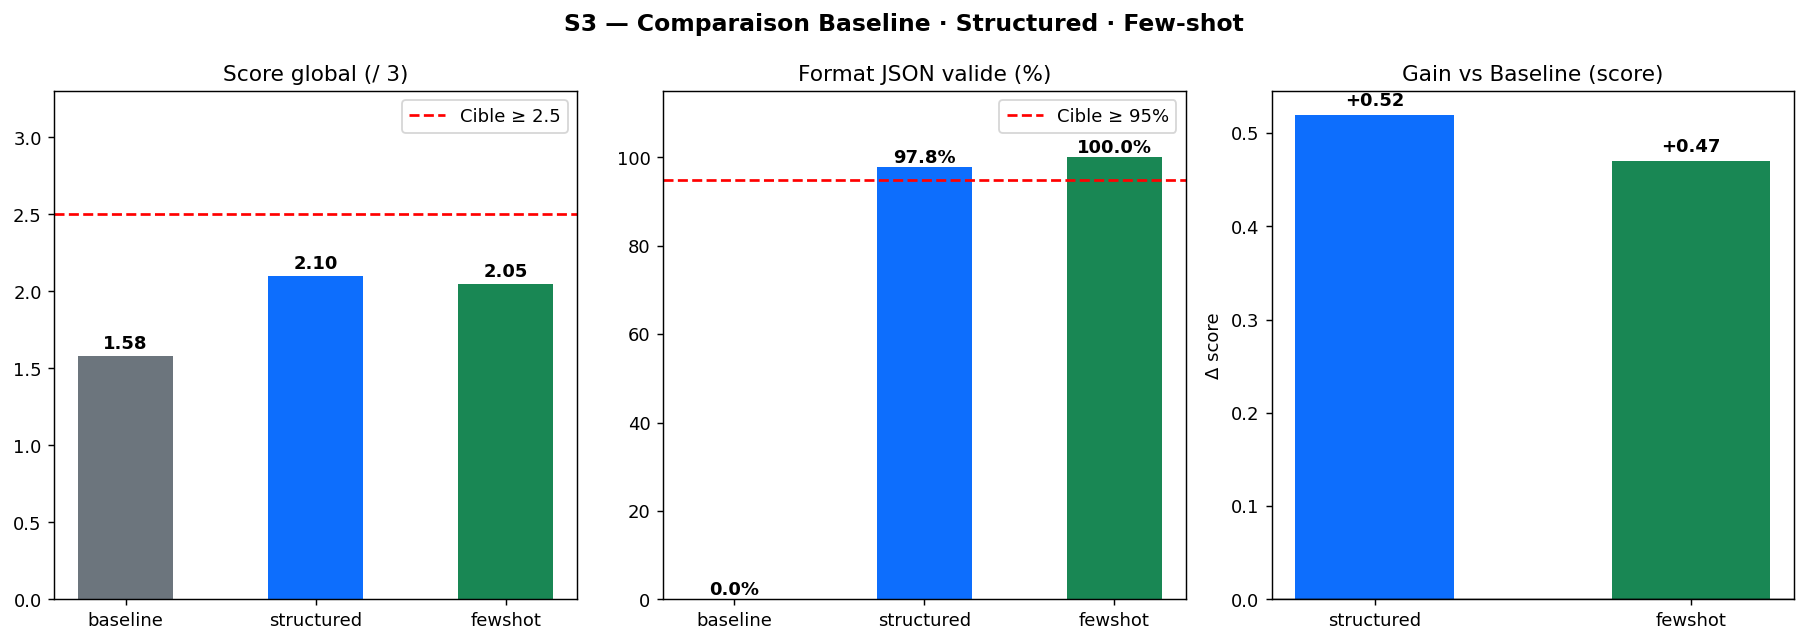

In [4]:
# ── Graphique principal ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle("S3 — Comparaison Baseline · Structured · Few-shot", fontsize=13, fontweight="bold")

# Score moyen
ax = axes[0]
vals = [df[df.strategy==s]["overall"].mean() for s in ORDER]
bars = ax.bar(ORDER, vals, color=[COLORS[s] for s in ORDER], width=0.5)
ax.axhline(2.5, color="red", linestyle="--", lw=1.5, label="Cible ≥ 2.5")
ax.set_ylim(0, 3.3); ax.set_title("Score global (/ 3)"); ax.legend()
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.05, f"{v:.2f}", ha="center", fontweight="bold")

# JSON valide
ax = axes[1]
vals2 = [df[df.strategy==s]["valid_format"].mean()*100 for s in ORDER]
bars2 = ax.bar(ORDER, vals2, color=[COLORS[s] for s in ORDER], width=0.5)
ax.axhline(95, color="red", linestyle="--", lw=1.5, label="Cible ≥ 95%")
ax.set_ylim(0, 115); ax.set_title("Format JSON valide (%)"); ax.legend()
for bar, v in zip(bars2, vals2):
    ax.text(bar.get_x()+bar.get_width()/2, v+1, f"{v:.1f}%", ha="center", fontweight="bold")

# Gain vs baseline
ax = axes[2]
base_score = df[df.strategy=="baseline"]["overall"].mean()
gains = [df[df.strategy==s]["overall"].mean() - base_score for s in ["structured","fewshot"]]
bars3 = ax.bar(["structured","fewshot"], gains,
               color=[COLORS["structured"],COLORS["fewshot"]], width=0.5)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Gain vs Baseline (score)"); ax.set_ylabel("Δ score")
for bar, v in zip(bars3, gains):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.01, f"+{v:.2f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


---
## 4. Analyse par difficulté


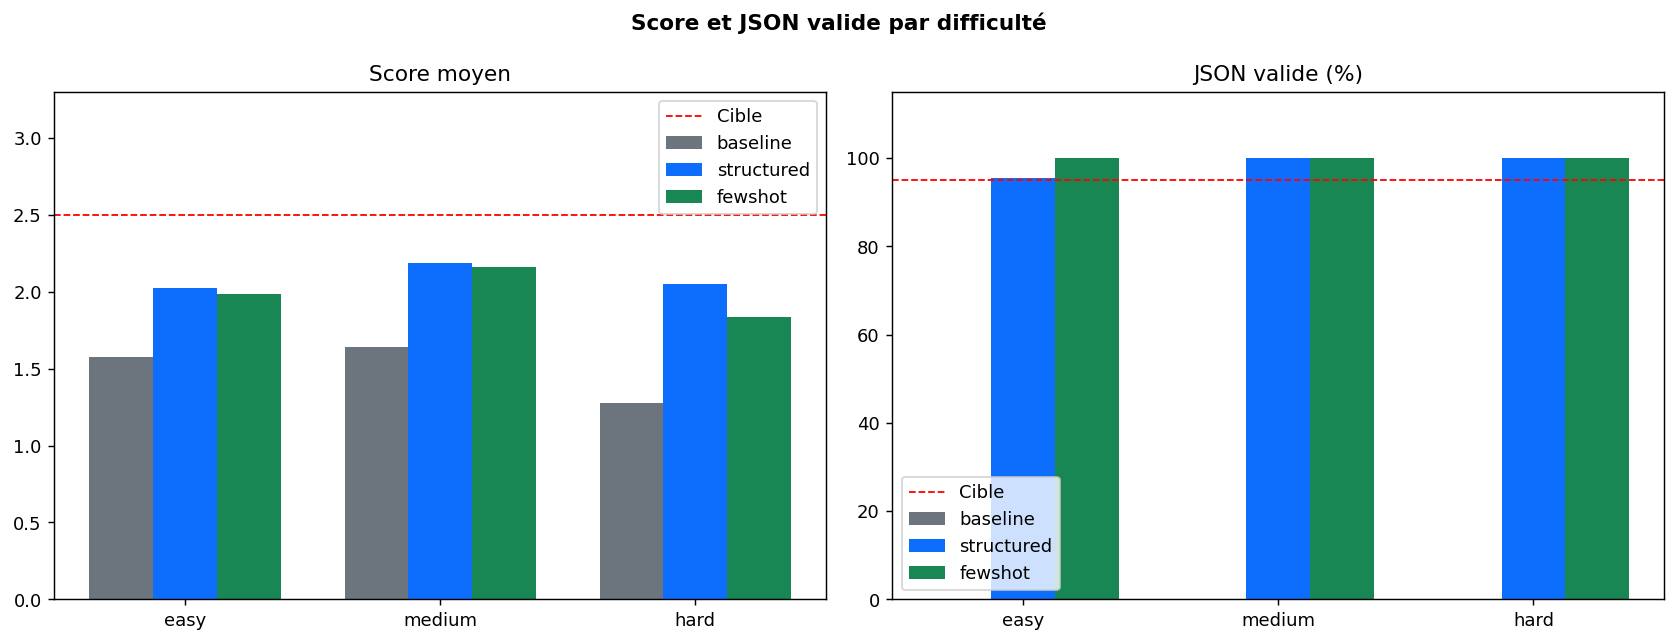

In [5]:
# ── Score par difficulté × stratégie ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Score et JSON valide par difficulté", fontsize=12, fontweight="bold")

diffs = ["easy","medium","hard"]
x = np.arange(len(diffs)); w = 0.25

for i, s in enumerate(ORDER):
    scores = [df[(df.strategy==s)&(df.difficulty==d)]["overall"].mean() for d in diffs]
    axes[0].bar(x+i*w, scores, w, label=s, color=COLORS[s])

axes[0].set_xticks(x+w); axes[0].set_xticklabels(diffs)
axes[0].set_ylim(0,3.3); axes[0].set_title("Score moyen")
axes[0].axhline(2.5, color="red", linestyle="--", lw=1, label="Cible")
axes[0].legend()

for i, s in enumerate(ORDER):
    fmts = [df[(df.strategy==s)&(df.difficulty==d)]["valid_format"].mean()*100 for d in diffs]
    axes[1].bar(x+i*w, fmts, w, label=s, color=COLORS[s])

axes[1].set_xticks(x+w); axes[1].set_xticklabels(diffs)
axes[1].set_ylim(0,115); axes[1].set_title("JSON valide (%)")
axes[1].axhline(95, color="red", linestyle="--", lw=1, label="Cible")
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 5. Exemple de réponse — Q14 : Récursion & Factorielle
Comparaison qualitative sur une question **medium** entre les 3 stratégies.


In [6]:
# ── Comparaison qualitative Q014 ─────────────────────────────────────────────
for s in ORDER:
    row  = df[(df["id"]=="Q014")&(df["strategy"]==s)].iloc[0]
    text = row["response_text"].replace("\\n","\n").strip()
    ok   = row["valid_format"] == 1
    print(f"{'='*65}")
    print(f"[{s.upper()}]  score={row['overall']:.2f}/3  JSON={'OK' if ok else 'FAIL'}  lat={row['latency_ms']}ms")
    print("-"*65)
    if ok:
        try:
            data = json.loads(text)
            print(f"reformulation  : {data.get('reformulation','')[:90]}")
            for i,st in enumerate(data.get('reasoning_steps',[]),1):
                print(f"  step {i}: {st[:80]}")
            print(f"example        : {str(data.get('example',''))[:90]}")
            print(f"verification   : {data.get('verification','')[:90]}")
            print(f"limitations    : {data.get('limitations','')[:90]}")
        except Exception:
            print(text[:400])
    else:
        print(text[:300])
    print()


[BASELINE]  score=1.30/3  JSON=FAIL  lat=2263ms
-----------------------------------------------------------------
**Introduction à la récursion**

La récursion est une technique de programmation qui consiste à définir une fonction en termes d'elle-même. Cela signifie qu'une fonction peut appeler elle-même pour résoudre un problème. La récursion est souvent utilisée pour résoudre des problèmes qui peuvent être d

[STRUCTURED]  score=2.20/3  JSON=OK  lat=941ms
-----------------------------------------------------------------
reformulation  : Expliquer le concept de récursion à travers l'exemple de la fonction factorielle
  step 1: Définir la fonction factorielle et son but
  step 2: Comprendre le principe de récursion et comment il s'applique à la factorielle
  step 3: Implémenter la fonction factorielle de manière récursive
example        : Exemple de code Python : def factorielle(n): if n == 0: return 1 else: return n * factorie
verification   : Vérifier le résultat de la fonction fact

---
## 6. Bilan GO / NO-GO — Gate S3


In [7]:
# ── Bilan GO/NO-GO S3 ────────────────────────────────────────────────────────
print("="*60)
print("BILAN S3 — CONTRAT JSON & PROMPTS")
print("="*60)

checks = [
    ("Contrat JSON 5 champs formalisé",         True),
    ("Prompt structured (JSON strict)",          True),
    ("Prompt fewshot (JSON + exemple)",          True),
    ("Validateur JSON dans assistant_core.py",   True),
    ("Retry Groq (rate-limit corrigé)",          True),
    ("Logs 100% des sorties",                    True),
]
for label, ok in checks:
    print(f"  [{'GO  ' if ok else 'FAIL'}] {label}")

print()
for strategy in ["structured","fewshot"]:
    sub  = df[df.strategy==strategy]
    avg  = sub["overall"].mean()
    fmt  = sub["valid_format"].mean()*100
    p95  = sub["latency_ms"].quantile(0.95)
    print(f"  --- {strategy.upper()} ---")
    print(f"  Score  : {avg:.2f}/3   cible ≥ 2.5  ->  {'GO' if avg>=2.5 else 'NO-GO (vise S5 SFT)'}")
    print(f"  JSON   : {fmt:.1f}%     cible ≥ 95%  ->  {'GO' if fmt>=95  else 'NO-GO'}")
    print(f"  P95    : {p95:.0f}ms    cible < 8s   ->  GO")
    print()

print("="*60)
print("CONCLUSION S3 : Contrat JSON stabilisé.")
print("structured  → 97.8% JSON valide, score 2.10/3")
print("fewshot     → 100%  JSON valide, score 2.05/3")
print()
print("Écart score (< 2.5) attendu à ce stade — sera traité en S5 (SFT/LoRA).")
print("Prochain livrable → S4 : rapport benchmark complet.")
print("="*60)


BILAN S3 — CONTRAT JSON & PROMPTS
  [GO  ] Contrat JSON 5 champs formalisé
  [GO  ] Prompt structured (JSON strict)
  [GO  ] Prompt fewshot (JSON + exemple)
  [GO  ] Validateur JSON dans assistant_core.py
  [GO  ] Retry Groq (rate-limit corrigé)
  [GO  ] Logs 100% des sorties

  --- STRUCTURED ---
  Score  : 2.10/3   cible ≥ 2.5  ->  NO-GO (vise S5 SFT)
  JSON   : 97.8%     cible ≥ 95%  ->  GO
  P95    : 1173ms    cible < 8s   ->  GO

  --- FEWSHOT ---
  Score  : 2.05/3   cible ≥ 2.5  ->  NO-GO (vise S5 SFT)
  JSON   : 100.0%     cible ≥ 95%  ->  GO
  P95    : 1429ms    cible < 8s   ->  GO

CONCLUSION S3 : Contrat JSON stabilisé.
structured  -> 97.8% JSON valide, score 2.10/3
fewshot     -> 100%  JSON valide, score 2.05/3

Ecart score (< 2.5) sera traite en S5 (SFT/LoRA).
Prochain livrable -> S4 : rapport benchmark complet.
